In [29]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics # 분류와 숫자 예측에 사용하는 모델 모음,모델의 예측 성능을 평가하는 도구 모음
from sklearn.neighbors import KNeighborsClassifier  #분류(가까운 이웃 데이터를 참고해 종류를 분류)
from sklearn.neighbors import KNeighborsRegressor   #예측(가까운 이웃데이터를 참고해 숫자를 예측)

from sklearn.preprocessing import PolynomialFeatures # 다항특성 (x², x₁ × x₂ 같은 특성을 추가)
from sklearn.preprocessing import OneHotEncoder      # 원핫인코딩(문자형 번주를 0과1로 변환)

from sklearn.linear_model import LinearRegression   #예측 (입력과 결과의 선형관례를 학습해 숫자를 예측)
from sklearn.linear_model import Ridge              #릿지 (계수가 지나치게 커지는 것을 억제하는 선형 회귀)
from sklearn.linear_model import Lasso              #라쏘 (일부 계수를 0으로 만들어 특성 선택에도 활용하는 선형 회귀)
from sklearn.linear_model import LogisticRegression #분류
from sklearn.linear_model import SGDClassifier

from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위 (실제값과 예측값의 차이를 절댓값으로 구한 뒤 평균 계산)
from sklearn.preprocessing import StandardScaler # 표준화 (각 특성을 평균 0, 표준편차 1 기준으로 표준화)
from sklearn.model_selection import train_test_split #(데이터를 학습용과 평가용으로 분리)
from scipy.special import expit                     #exip:이진분류함수
from scipy.special import softmax                   #softmax: 다중분류함수

# 결정트리
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree                  #그래프지원

# 교차검증
from sklearn.model_selection import cross_validate      # 자동 반복

# 분할기
from sklearn.model_selection import StratifiedKFold

from sklearn.model_selection import GridSearchCV

# 모델저장 - 실행파일
from sklearn.pipeline import make_pipeline
import joblib

In [30]:
#1. 파일 불러오기
fish = pd.read_csv('data/fish_logistic.csv')
fish.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [31]:
# 1-1 데이터 정보 탐색
fish.info()

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Species   159 non-null    str    
 1   Weight    159 non-null    float64
 2   Length    159 non-null    float64
 3   Diagonal  159 non-null    float64
 4   Height    159 non-null    float64
 5   Width     159 non-null    float64
dtypes: float64(5), str(1)
memory usage: 7.6 KB


In [32]:
fish.describe()

,Weight,Length,Diagonal,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,28.415723,31.227044,8.970994,4.417486
std,357.978317,10.716328,11.610246,4.286208,1.685804
min,0.000000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,63.400000,68.000000,18.957000,8.142000


In [33]:
# 2. data, label분리
data= fish[fish.columns[1:]].values
label = fish['Species'].values

In [34]:
# 3. 학습, 테스트 데이터 분리
train_data, test_data, train_label, test_label = train_test_split(data, label)

In [35]:
# 4. logisticRegression전 정규화 작업 필수

ss=StandardScaler()
ss.fit(train_data)

train_scaled= ss.transform(train_data)
test_scaled= ss.transform(test_data)

In [36]:
# 5. logisticRegression 모델 학습
lr=LogisticRegression(C=20,max_iter=1000)
lr.fit(train_scaled, train_label)

print("train정확도:", lr.score(train_scaled, train_label))
print("test정확도:", lr.score(test_scaled, test_label))

train정확도: 0.9243697478991597
test정확도: 0.875


In [37]:
# 5-1. 규제 C값 찾기
train_score =[]
test_score= []
cc=[0.001,0.01,0.1,1,10,20,50,100]
for c in cc:
    lr=LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled, train_label)

    train_score.append(lr.score(train_scaled, train_label))
    test_score.append(lr.score(test_scaled, test_label))

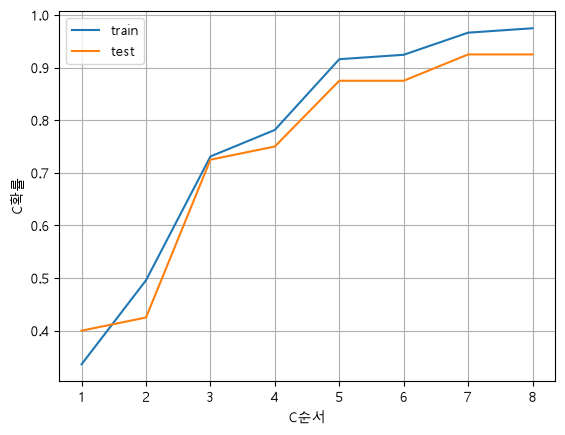

In [38]:
# 5-2 그래프

list1=list(range(1,9))

plt.plot(list1,train_score)
plt.plot(list1,test_score)

plt.xlabel('C순서')
plt.ylabel('C확률')
plt.legend(['train','test'])
plt.grid()
plt.show()

In [39]:
lr.classes_ # 출력되는 확률 순서

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [40]:
# 실제 입력받아 예측하시오
predict= lr.predict(test_scaled[:1])
print('분류생선:', predict)

proba= lr. predict_proba(test_scaled[:1])

# if문은 넣어서 확인
if predict[0]=="Bream":
    result = proba[0][0]
elif predict[0]=="Parkki":
    result = proba[0][1]
elif predict[0]=="Perch":
    result = proba[0][2]
elif predict[0]=="Pike":
    result = proba[0][3]
elif predict[0]=="Roach":
    result = proba[0][4]
elif predict[0]=="Smelt":
    result = proba[0][5]
else:
    result = proba[0][6]


print("확률:",result)

분류생선: ['Smelt']
확률: 0.9722778008823332


In [ ]:
# 새로운 데이터를 분류하려면
# 1. 정규화
# 2. 데이터 predict

In [41]:
proba= lr. predict_proba(test_scaled[:1])
proba
decisions = lr.decision_function(train_scaled[:1])
decisions

# 0~1 사이의 값이 나옴
soft1=softmax(decisions, axis=1)
soft1
print(np.round(soft1, decimals=3))

[[0.    0.053 0.246 0.    0.585 0.102 0.014]]
